<a href="https://colab.research.google.com/github/sabaardan/Swiss-inflation-froecast/blob/main/notebooks/Swiss_Inflation_Forecast.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [58]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox

warnings.filterwarnings("ignore", category=FutureWarning)


os.makedirs("figures", exist_ok=True)

# **Data**

I download the national consumer price index directly from the SNB data portal.The file contains two series: LD2010100: the national CPI index (December 2025 = 100), VVP: the SNB's year-on-year inflation rate.

In [59]:
url = "https://data.snb.ch/api/cube/plkopr/data/csv/en"

df = pd.read_csv(url, sep=";", skiprows=3)
print(df.head())
print(df.tail())

      Date         D0      Value
0  1921-01  LD2010100  19.588398
1  1921-01        VVP        NaN
2  1921-02  LD2010100  19.361351
3  1921-02        VVP        NaN
4  1921-03  LD2010100  19.098022
         Date         D0       Value
2535  2026-08        VVP    0.807246
2536  2026-09  LD2010100  101.473700
2537  2026-09        VVP    0.990059
2538  2026-10  LD2010100  101.682300
2539  2026-10        VVP    1.456053


In [60]:
cpi_df = df[df["D0"] == "LD2010100"].copy()
cpi_df["Date"] = pd.to_datetime(cpi_df["Date"])      # text -> dates
cpi_df = cpi_df.set_index("Date")
cpi_full = pd.to_numeric(cpi_df["Value"])             # full history (1921-)
cpi_full.name = "cpi"

# Estimation sample: from 1999-01, so that y/y inflation starts in 2000-01
cpi = cpi_full.loc["1999-01":]

print("Observations (full):", len(cpi_full))
print("First month:", cpi_full.index[0].strftime("%Y-%m"))
print("Last month: ", cpi_full.index[-1].strftime("%Y-%m"))

Observations (full): 1270
First month: 1921-01
Last month:  2026-10


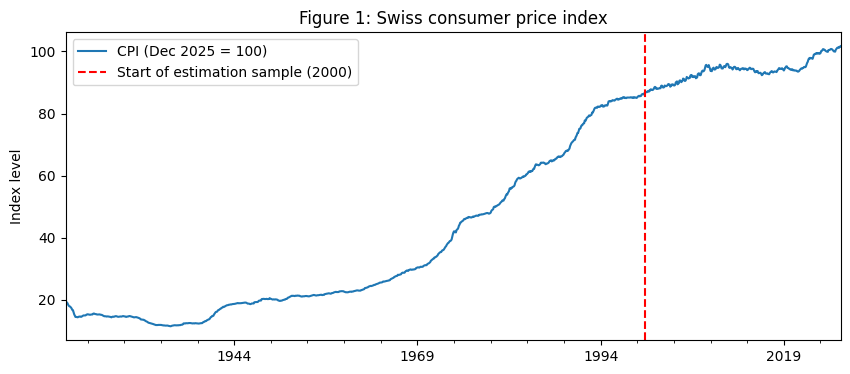

In [61]:
fig, ax = plt.subplots(figsize=(10, 4))
cpi_full.plot(ax=ax, label="CPI (Dec 2025 = 100)")
ax.axvline(pd.Timestamp("2000-01-01"), color="red", linestyle="--",
           label="Start of estimation sample (2000)")
ax.set_title("Figure 1: Swiss consumer price index")
ax.set_xlabel("")
ax.set_ylabel("Index level")
ax.legend()
plt.show()

# **Seasonal adjustment and transformation for the model**

Monthly consumer prices have a regular seasonal pattern. I remove it with an STL decomposition of the log CPI, which splits the series into a trend, a seasonal and a remainder component. All further steps use the seasonally adjusted CPI.




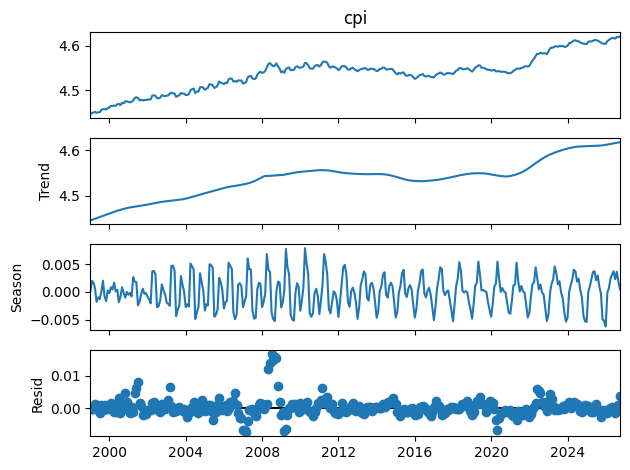

In [62]:
#Log CPI monthly frequency
log_cpi = np.log(cpi).asfreq("MS")

#STL decomposition (period = 12 months)
stl = STL(log_cpi, period=12, robust=True).fit()
stl.plot()
plt.show()


In [63]:
#Seasonally adjusted log CPI = log CPI minus the seasonal component
log_cpi_sa = log_cpi - stl.seasonal

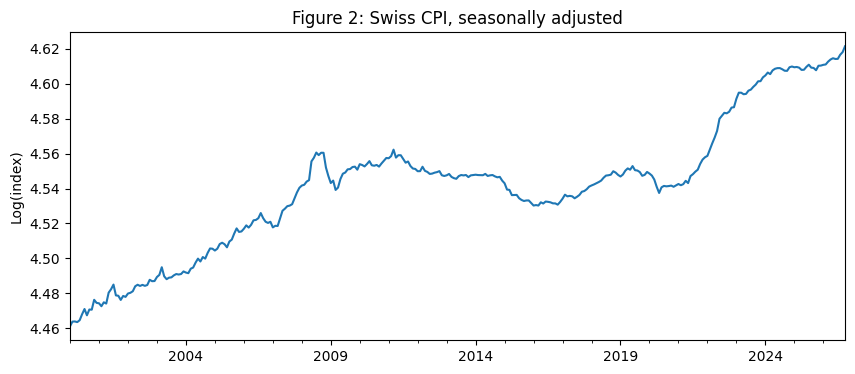

In [64]:
# a) Log level
fig, ax = plt.subplots(figsize=(10, 4))
log_cpi_sa.loc["2000-01":].plot(ax=ax)
ax.set_title("Figure 2: Swiss CPI, seasonally adjusted")
ax.set_ylabel("Log(index)")
ax.set_xlabel("")
plt.show()

Starting from 2000 until 2008, there is a steady increase in log CPI level.
in 2009-2021 period, log CPI level is roughly flat. Then, during 2021-2023 there is a sharp increase. However, after 2024 log CPI level is flatter.
Thus, log CPI level is clearly non-stationary.

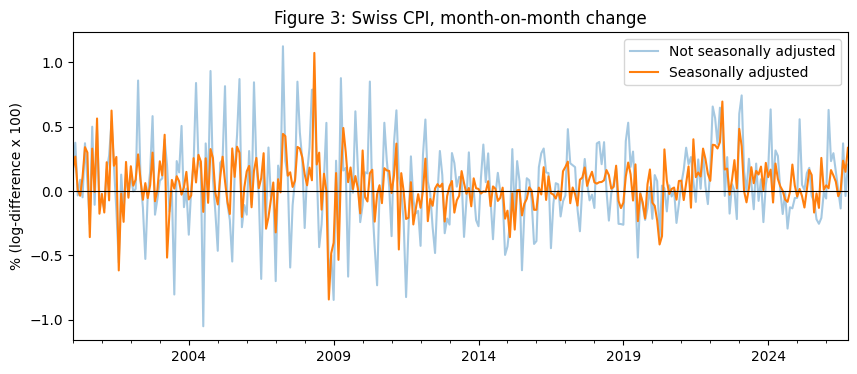

In [65]:
# b) Month-on-month change, before and after seasonal adjustment
dcpi = (100 * log_cpi_sa.diff()).loc["2000-01":]
dcpi.name = "m/m inflation (SA)"
dcpi_raw = (100 * log_cpi.diff()).loc["2000-01":]

fig, ax = plt.subplots(figsize=(10, 4))
dcpi_raw.plot(ax=ax, alpha=0.4, label="Not seasonally adjusted")
dcpi.plot(ax=ax, label="Seasonally adjusted")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Figure 3: Swiss CPI, month-on-month change")
ax.set_ylabel("% (log-difference x 100)")
ax.set_xlabel("")
ax.legend()
plt.show()

The adjusted series fluctuates around a small positive mean with no trend.

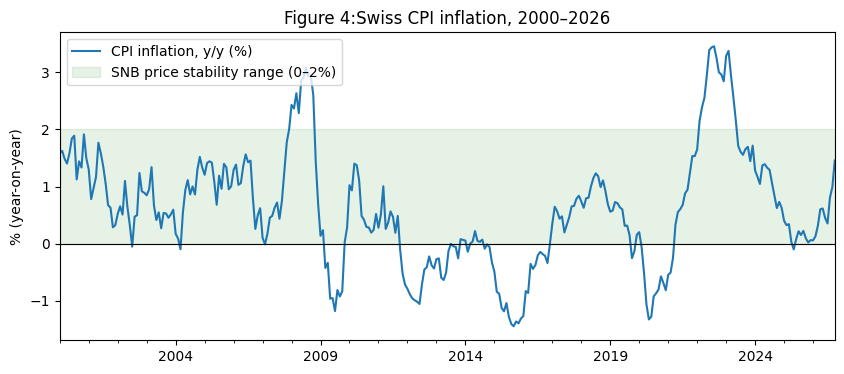

In [66]:
# c) Year-on-year change
infl_full = cpi_full.pct_change(periods=12, fill_method=None) * 100
infl = infl_full.loc["2000-01":]
infl.name = "inflation"

fig, ax = plt.subplots(figsize=(10, 4))
infl.plot(ax=ax, label="CPI inflation, y/y (%)")
ax.axhspan(0, 2, color="green", alpha=0.1, label="SNB price stability range (0–2%)")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Figure 4:Swiss CPI inflation, 2000–2026")
ax.set_xlabel("")
ax.set_ylabel("% (year-on-year)")
ax.legend(loc="upper left")
plt.savefig("figures/inflation_since_2000.png", dpi=150, bbox_inches="tight")
plt.show()

In [67]:
# Key statistics of y/y inflation (2000-)
key_stats = pd.DataFrame({
    "Statistic": ["Mean inflation",
                  "Standard deviation",
                  "Peak",
                  "Lowest",
                  "Share of months inside 0–2%",
                  "Share of months below 0%",
                  "Share of months above 2%",
                  "Latest value"],
    "Value (%)": [infl.mean(),
                  infl.std(),
                  infl.max(),
                  infl.min(),
                  ((infl >= 0) & (infl <= 2)).mean() * 100,
                  (infl < 0).mean() * 100,
                  (infl > 2).mean() * 100,
                  infl.iloc[-1]],
    "Date": ["2000–2026", "2000–2026",
             infl.idxmax().strftime("%Y-%m"),
             infl.idxmin().strftime("%Y-%m"),
             "2000–2026", "2000–2026", "2000–2026",
             infl.index[-1].strftime("%Y-%m")],
}).set_index("Statistic")
key_stats.round(2)

,Value (%),Date
Statistic,,
Mean inflation,0.61,2000–2026
Standard deviation,1.01,2000–2026
Peak,3.45,2022-08
Lowest,-1.44,2015-09
Share of months inside 0–2%,66.15,2000–2026
Share of months below 0%,25.47,2000–2026
Share of months above 2%,8.39,2000–2026
Latest value,1.46,2026-10


# **Unit root tests**

To test formally whether the CPI is difference-stationary, I perform augmented Dickey–Fuller (ADF) tests. The null hypothesis is a unit root (non-stationarity). Because the log CPI has an upward trend, the test in levels includes a constant and a trend; the test in first differences includes a constant only. Lags are selected with the BIC (maximum 10).




In [68]:
adf_level = adfuller(log_cpi_sa.loc["2000-01":], regression="ct", maxlag=10, autolag="BIC")
adf_diff  = adfuller(dcpi, regression="c", maxlag=10, autolag="BIC")

adf_table = pd.DataFrame({
    "Series": ["Log CPI (SA), constant + trend", "m/m inflation (SA), constant"],
    "ADF statistic": [adf_level[0], adf_diff[0]],
    "p-value": [adf_level[1], adf_diff[1]],
    "Lags": [adf_level[2], adf_diff[2]],
}).set_index("Series")
adf_table.round(3)

,ADF statistic,p-value,Lags
Series,,,
"Log CPI (SA), constant + trend",-1.298,0.888,2
"m/m inflation (SA), constant",-9.770,0.000,1


Log CPI (SA) can't reject the null hypothesis. Therefore, the serie is non-stationary.
In the other hand, Month-on-Month (SA)rejects the unit toor. Hnece, it is stationary. Therefore, the series is difference stationary.

# **Model selection and residual diagnostics**

**Simple starting model: AR(1)**

I start with an AR(1) model with a constant for monthly inflation and inspect its residuals.

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0505      0.013      3.825      0.000       0.025       0.076
ar.L1          0.1633      0.049      3.349      0.001       0.068       0.259
sigma2         0.0391      0.002     21.399      0.000       0.035       0.043


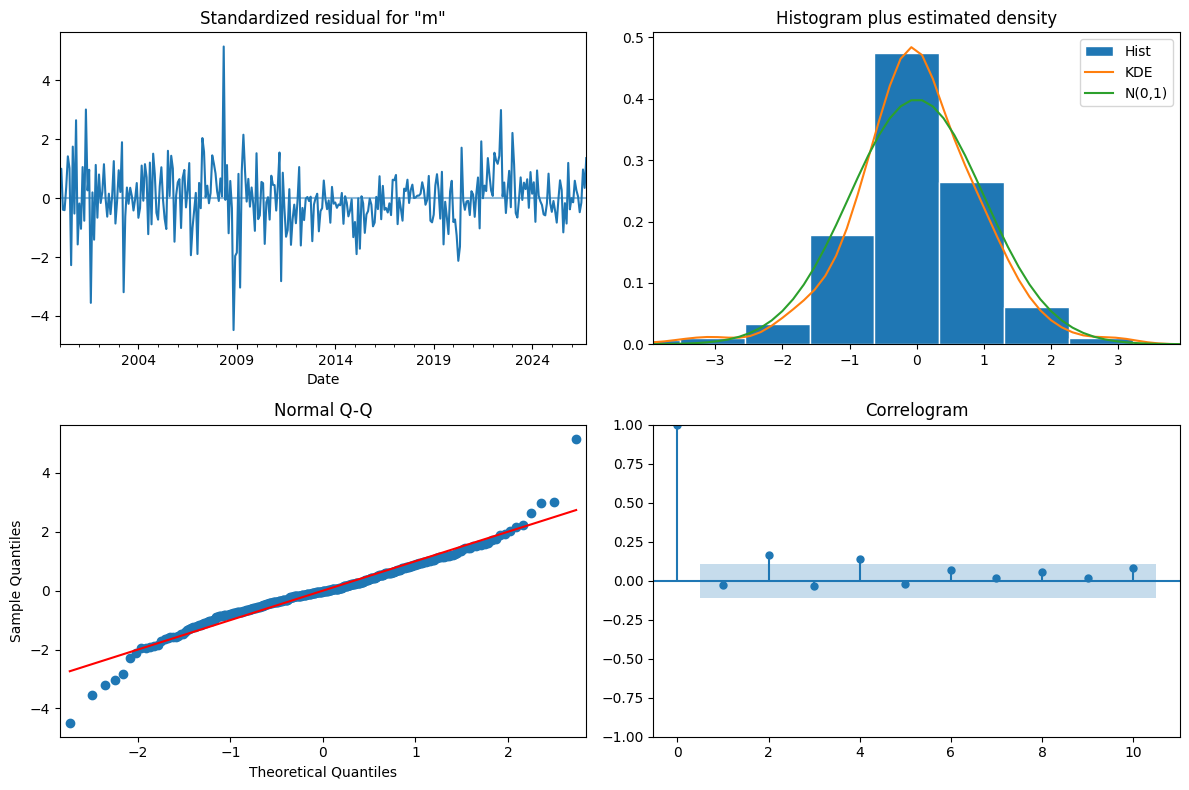

,lb_stat,lb_pvalue
12,23.171,0.017
24,32.177,0.097


In [69]:
model_ar1 = ARIMA(dcpi, order=(1, 0, 0), trend="c").fit()
print(model_ar1.summary().tables[1])

model_ar1.plot_diagnostics(figsize=(12, 8))
plt.tight_layout()
plt.show()

acorr_ljungbox(model_ar1.resid, lags=[12, 24], model_df=1, return_df=True).round(3)

As illustrated in the summary table, AR(1) coefficient is statistically significant. However, residuals shows significant autocorrelation at lags 2 and 4 (correlogram), and Ljung-Box test rejects the null hypothesis of no autocorrelation at 12 lags (p=0.017). Therefore, the AR(1) model can be improved.

**Lag selection with information criteria**

I estimate all ARMA(p,q) models with p, q = 0,…,6 (including a constant) and compare the Akaike (AIC) and Bayesian (BIC) information criteria. The BIC penalises additional parameters more strongly and tends to select smaller models, which usually forecast better, so I use it as the main criterion.

In [70]:
max_p= 6
max_q=6
aic = pd.DataFrame(np.nan, index=range(max_p + 1), columns=range(max_q + 1))
bic = aic.copy()
aic.index.name = bic.index.name = "p (AR)"
aic.columns.name = bic.columns.name = "q (MA)"

for p in range(max_p + 1):
    for q in range(max_q + 1):
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                res = ARIMA(dcpi, order=(p, 0, q), trend="c").fit()
            aic.loc[p, q] = res.aic
            bic.loc[p, q] = res.bic
        except Exception as err:
            print(f"ARMA({p},{q}) failed: {err}")

p_aic, q_aic = aic.stack().idxmin()
p_bic, q_bic = bic.stack().idxmin()
print(f"AIC selects ARMA({p_aic},{q_aic})")
print(f"BIC selects ARMA({p_bic},{q_bic})")

AIC selects ARMA(4,0)
BIC selects ARMA(2,0)


In [71]:
#BIC table (minimum in green)
bic.round(1).style.highlight_min(axis=None, color="lightgreen")

q (MA),0,1,2,3,4,5,6
p (AR),,,,,,,
0,-109.900000,-110.600000,-114.300000,-108.600000,-108.000000,-102.200000,-97.100000
1,-112.800000,-114.700000,-110.600000,-102.700000,-102.300000,-98.000000,-93.200000
2,-115.600000,-112.300000,-107.900000,-104.400000,-98.700000,-89.000000,-87.300000
3,-110.100000,-107.000000,-104.200000,-98.600000,-92.900000,-87.300000,-81.600000
4,-108.800000,-103.200000,-98.600000,-92.700000,-87.200000,-81.600000,-81.400000
5,-103.100000,-97.600000,-93.000000,-87.800000,-81.600000,-75.900000,-74.500000
6,-97.700000,-93.300000,-87.800000,-81.600000,-75.900000,-70.500000,-70.100000


**Selected model and residual diagnostics**


The BIC selects an AR(2) model.

In [72]:
model = ARIMA(dcpi, order=(p_bic, 0, q_bic), trend="c").fit()
print(model.summary().tables[1])
print(model.summary().tables[2])

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0511      0.016      3.275      0.001       0.020       0.082
ar.L1          0.1374      0.050      2.759      0.006       0.040       0.235
ar.L2          0.1622      0.053      3.072      0.002       0.059       0.266
sigma2         0.0380      0.002     21.410      0.000       0.035       0.042
Ljung-Box (L1) (Q):                   0.01   Jarque-Bera (JB):               192.57
Prob(Q):                              0.93   Prob(JB):                         0.00
Heteroskedasticity (H):               0.41   Skew:                            -0.05
Prob(H) (two-sided):                  0.00   Kurtosis:                         6.79


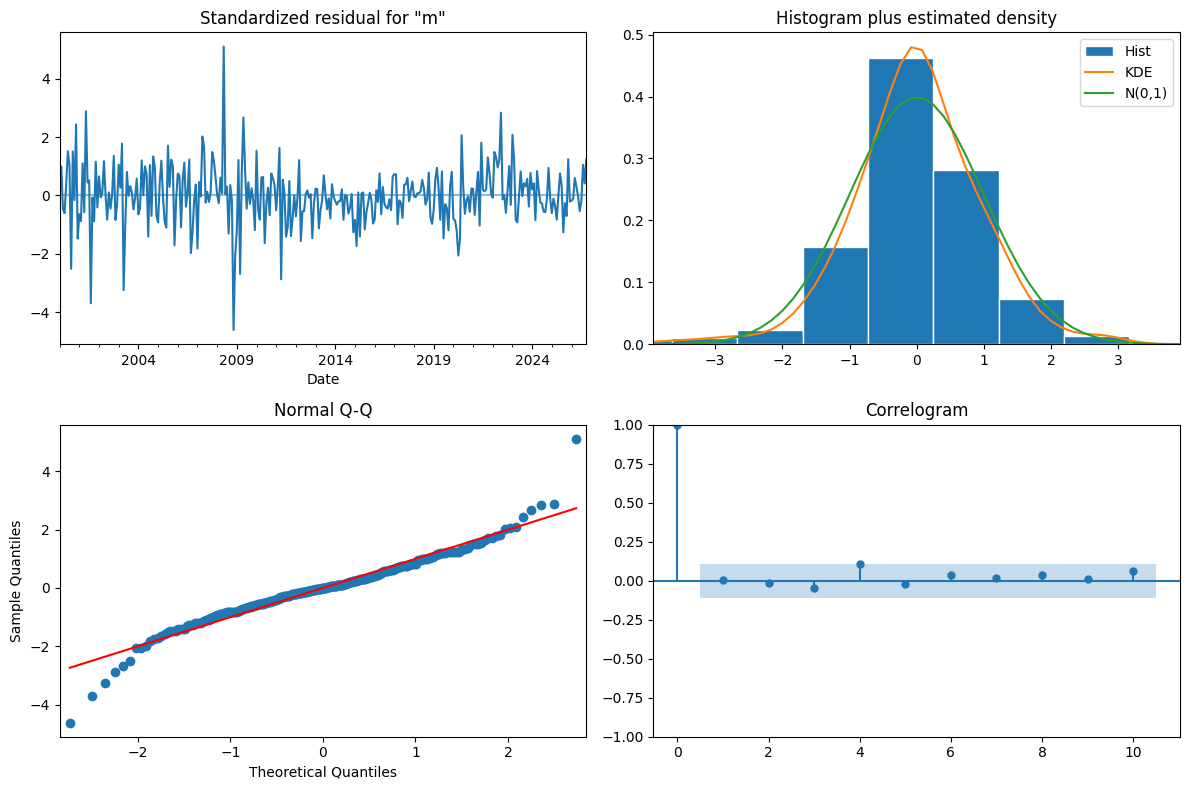

,lb_stat,lb_pvalue
12,9.249,0.509
24,21.721,0.477


In [73]:
model.plot_diagnostics(figsize=(12, 8))
plt.tight_layout()
plt.show()
acorr_ljungbox(model.resid, lags=[12, 24], model_df=p_bic + q_bic, return_df=True).round(3)

In selected model, AR(2), both autoregressive coefficients are statistically significant.The residuals show no significant autocorrelation.The Ljung–Box test does not reject the null hypothesis of no autocorrelation at 12 lags (p = 0.51) or 24 lags (p = 0.48).

# **Inflation forecast using AR(2) and simulation of uncertainty**

I forecast monthly inflation for the next 14 months (November 2026 – December 2027). To convey uncertainty, I simulate 5,000 possible future paths from the estimated model (Monte Carlo, normally distributed shocks). Each path is converted back to a CPI level (cumulative sum of the log-differences) and then to year-on-year inflation. The percentiles across paths give the interval forecasts.

In [74]:
H = 14        #forecast horizon in months
NSIM = 5000   #number of simulated paths

#Point forecast (m/m)
fc = model.get_forecast(steps=H)

#Simulated paths of m/m inflation, starting after the last observation
sims = model.simulate(nsimulations=H, repetitions=NSIM, anchor="end")
sims = pd.DataFrame(np.asarray(sims).reshape(H, NSIM), index=fc.predicted_mean.index)

#Check: mean of simulations ~ point forecast
pd.DataFrame({"Point forecast": fc.predicted_mean,
              "Mean of simulations": sims.mean(axis=1)}).round(3).head()

,Point forecast,Mean of simulations
2026-11-01,0.106,0.107
2026-12-01,0.105,0.104
2027-01-01,0.067,0.068
2027-02-01,0.062,0.062
2027-03-01,0.055,0.053


The mean of the 5,000 simulated paths matches the analytic point forecast,
which confirms the simulation. Monthly inflation is forecast at about 0.11%
in November and December 2026, above its long-run mean of 0.05%, reflecting
the strong price increases of recent months. It then gradually returns
towards the mean in 2027.

In [75]:
#Convert m/m forecasts (log-differences x 100) into log CPI paths, y/y inflation and annual inflation. Used for all models below.
def build_paths(mm_future):

    hist = log_cpi_sa.loc["2025-01":]
    future = hist.iloc[-1] + mm_future.cumsum() / 100
    hist_paths = pd.DataFrame(np.repeat(hist.values[:, None], mm_future.shape[1], axis=1),
                              index=hist.index, columns=mm_future.columns)
    return pd.concat([hist_paths, future])

def to_yoy(paths):

    return 100 * (np.exp(paths - paths.shift(12)) - 1)

def to_annual(paths):

    annual = np.exp(paths).resample("YS").mean()
    growth = (annual.pct_change() * 100).dropna()
    growth.index = growth.index.year
    return growth


paths = build_paths(sims)
yoy_fcst = to_yoy(paths).loc[sims.index]

levels = [0.025, 0.10, 0.15, 0.25, 0.5, 0.75, 0.85, 0.90, 0.975]
fan = yoy_fcst.quantile(levels, axis=1).T

fan_table = fan[[0.025, 0.5, 0.975]].copy()
fan_table.columns = ["95% lower", "Median", "95% upper"]
fan_table.index = fan_table.index.strftime("%Y-%m")
fan_table.round(2)

,95% lower,Median,95% upper
2026-11,0.85,1.23,1.62
2026-12,0.74,1.32,1.91
2027-01,0.57,1.35,2.12
2027-02,0.43,1.40,2.32
2027-03,0.19,1.30,2.39
2027-04,-0.00,1.23,2.44
2027-05,-0.14,1.20,2.52
2027-06,-0.15,1.28,2.70
2027-07,-0.19,1.33,2.87
2027-08,-0.48,1.15,2.74


**Fan chart and probabilities**

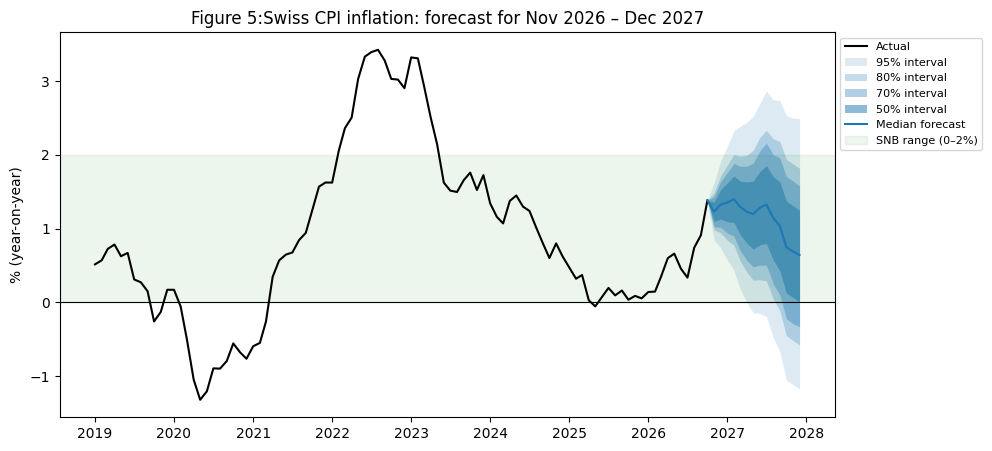

In [76]:
#y/y history from the seasonally adjusted CPI
infl_sa = 100 * (np.exp(log_cpi_sa - log_cpi_sa.shift(12)) - 1)
hist_plot = infl_sa.loc["2019-01":]

#Connect the fan to the last observation
last = hist_plot.iloc[[-1]]
fan_plot = pd.concat([pd.DataFrame({c: last.values for c in fan.columns}, index=last.index), fan])

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(hist_plot.index, hist_plot, color="black", label="Actual")
for (lo, hi), a, lab in zip([(0.025, 0.975), (0.10, 0.90), (0.15, 0.85), (0.25, 0.75)],
                            [0.15, 0.25, 0.35, 0.5],
                            ["95%", "80%", "70%", "50%"]):
    ax.fill_between(fan_plot.index, fan_plot[lo], fan_plot[hi],
                    color="tab:blue", alpha=a, linewidth=0, label=f"{lab} interval")
ax.plot(fan_plot.index, fan_plot[0.5], color="tab:blue", label="Median forecast")
ax.axhspan(0, 2, color="green", alpha=0.07, label="SNB range (0–2%)")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Figure 5:Swiss CPI inflation: forecast for Nov 2026 – Dec 2027")
ax.set_ylabel("% (year-on-year)")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1), fontsize=8)
plt.savefig("figures/fan_chart.png", dpi=150, bbox_inches="tight")
plt.show()

The median forecast of year-on-year inflation remains at around 1.2–1.4% until
mid-2027 and then declines to about 0.7% by December 2027, as the strong price
increases of August–October 2026 drop out of the year-on-year comparison (base
effects). Uncertainty increases with the horizon: the 95% interval widens to
about −1.2% to 2.5% by the end of 2027.


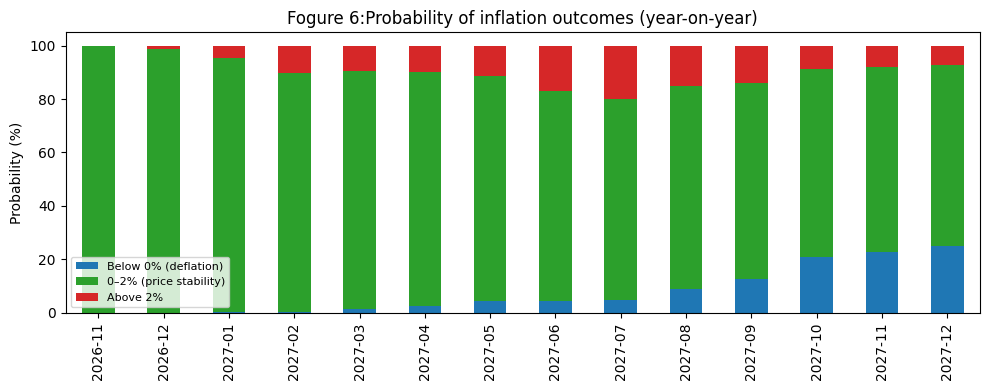

In [77]:
#Probability of inflation outcomes per month
prob = pd.DataFrame({
    "Below 0% (deflation)":   (yoy_fcst < 0).mean(axis=1),
    "0–2% (price stability)": ((yoy_fcst >= 0) & (yoy_fcst <= 2)).mean(axis=1),
    "Above 2%":               (yoy_fcst > 2).mean(axis=1),
}) * 100

ax = prob.set_index(prob.index.strftime("%Y-%m")).plot(
    kind="bar", stacked=True, figsize=(10, 4),
    color=["tab:blue", "tab:green", "tab:red"])
ax.set_title("Fogure 6:Probability of inflation outcomes (year-on-year)")
ax.set_ylabel("Probability (%)")
ax.set_xlabel("")
ax.legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.savefig("figures/probabilities.png", dpi=150, bbox_inches="tight")
plt.show()

The probability chart shows that inflation is very likely to remain within the
SNB's 0–2% range in the coming months. The balance of risks shifts over the
forecast horizon: in mid-2027, the main risk is inflation above 2% (about 20%),
whereas by the end of 2027 the probability of negative inflation rises to about
25%.

**Extended Model: adding oil prices**

The recent rise in inflation is mainly driven by energy prices, which a univariate model cannot identify. I therefore add the oil price as an explanatory variable in a direct forecasting regression: for each horizon h = 1,…,14, I regress monthly inflation h months ahead on the two latest values of monthly inflation (as in the AR(2)) and the latest monthly change in the oil price (Brent, converted to Swiss francs). Each regression delivers the forecast for one horizon.

Data: Brent crude oil price (daily, USD per barrel, FRED series `DCOILBRENTEU`), averaged to monthly frequency, and the CHF/USD exchange rate (monthly, FRED series `EXSZUS`).

Oil data until: 2026-10


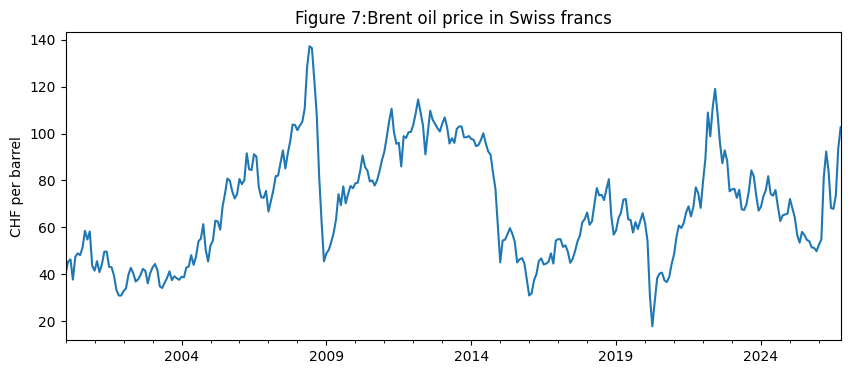

In [78]:
fred = "https://fred.stlouisfed.org/graph/fredgraph.csv?id="
brent = pd.read_csv(fred + "DCOILBRENTEU", index_col=0, parse_dates=True, na_values=".").iloc[:, 0]
chfusd = pd.read_csv(fred + "EXSZUS", index_col=0, parse_dates=True, na_values=".").iloc[:, 0]

#Monthly average oil price, converted to Swiss francs
oil_chf = (brent.resample("MS").mean() * chfusd).dropna()
oil_chf.name = "Brent oil price (CHF per barrel)"

#Monthly oil price inflation (log-difference x 100), same sample as the CPI
doil = (100 * np.log(oil_chf).diff()).loc["2000-01":dcpi.index[-1]]
print("Oil data until:", oil_chf.index[-1].strftime("%Y-%m"))

fig, ax = plt.subplots(figsize=(10, 4))
oil_chf.loc["2000-01":].plot(ax=ax)
ax.set_title("Figure 7:Brent oil price in Swiss francs")
ax.set_ylabel("CHF per barrel")
ax.set_xlabel("")
plt.show()

In [79]:
import statsmodels.api as sm

#Predictors at time t: inflation (t and t-1) and oil price inflation (t)
X = pd.DataFrame({"infl_t": dcpi,
                  "infl_t-1": dcpi.shift(1),
                  "oil_t": doil})
X = sm.add_constant(X)

#Example for h = 1: inflation next month on today's predictors
data1 = pd.concat([dcpi.shift(-1).rename("infl_t+1"), X], axis=1).dropna()
direct1 = sm.OLS(data1["infl_t+1"], data1.drop(columns="infl_t+1")).fit()
print(direct1.summary().tables[1])

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0387      0.010      3.702      0.000       0.018       0.059
infl_t        -0.0200      0.054     -0.373      0.710      -0.125       0.085
infl_t-1       0.1908      0.050      3.789      0.000       0.092       0.290
oil_t          0.0084      0.001      8.407      0.000       0.006       0.010


The oil price is a highly significant predictor of next month's inflation, a 10% increase in the oil price (in CHF) raises monthly inflation by about 0.08 percentage points in the following month.
Once the oil price is included, last month's inflation is no longer
significant, which suggests that much of the short-run persistence captured
by the AR(2) reflects energy price movements.

In [80]:
#Direct forecasts for every horizon h = 1,...,H
x_last = X.iloc[[-1]]
print(x_last.round(3))

fc_oil = pd.Series(index=sims.index, dtype=float)
for h in range(1, H + 1):
    data_h = pd.concat([dcpi.shift(-h).rename("y"), X], axis=1).dropna()
    reg = sm.OLS(data_h["y"], data_h.drop(columns="y")).fit()
    fc_oil.iloc[h - 1] = reg.predict(x_last).iloc[0]

#Convert to y/y inflation
paths_oil = build_paths(fc_oil.to_frame())
yoy_oil = to_yoy(paths_oil).loc[sims.index].iloc[:, 0]

            const  infl_t  infl_t-1  oil_t
2026-10-01    1.0   0.336     0.149  9.302


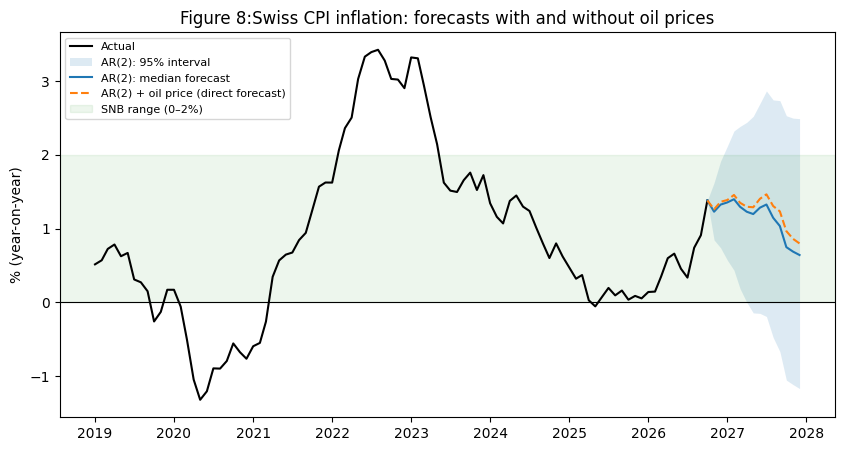

In [81]:
#Comparing AR(2) vs. AR(2) + oil price
oil_plot = pd.concat([last, yoy_oil])
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(hist_plot.index, hist_plot, color="black", label="Actual")
ax.fill_between(fan_plot.index, fan_plot[0.025], fan_plot[0.975],
                color="tab:blue", alpha=0.15, linewidth=0, label="AR(2): 95% interval")
ax.plot(fan_plot.index, fan_plot[0.5], color="tab:blue", label="AR(2): median forecast")
ax.plot(oil_plot.index, oil_plot, color="tab:orange", linestyle="--",
        label="AR(2) + oil price (direct forecast)")
ax.axhspan(0, 2, color="green", alpha=0.07, label="SNB range (0–2%)")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Figure 8:Swiss CPI inflation: forecasts with and without oil prices")
ax.set_ylabel("% (year-on-year)")
ax.legend(loc="upper left", fontsize=8)
plt.savefig("figures/model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

Including the oil price raises the forecast slightly, by about 0.05–0.15
percentage points over the whole horizon, because the strong increase in oil
prices in October 2026 (+9% in CHF) feeds into inflation in the following
months. The difference is small relative to the forecast uncertainty.

# **Annual Forecast**

Annual inflation is the percentage change in the annual average CPI. For 2022–2025 I use actual data; for 2026 (10 months observed) and 2027 I compute the annual average for each simulated path of the AR(2) and report the median and the 95% interval.

In [82]:
#History (official CPI)
hist_annual = cpi.resample("YS").mean().pct_change() * 100
hist_annual.index = hist_annual.index.year

#AR(2): annual inflation for every simulated path
annual_growth = to_annual(paths)

fc_years = [2026, 2027]
annual_table = pd.DataFrame({
    "Inflation (%)": list(hist_annual.loc[2022:2025]) + list(annual_growth.loc[fc_years].median(axis=1)),
    "95% lower":     [np.nan] * 4 + list(annual_growth.loc[fc_years].quantile(0.025, axis=1)),
    "95% upper":     [np.nan] * 4 + list(annual_growth.loc[fc_years].quantile(0.975, axis=1)),
    "Type":          ["Actual"] * 4 + ["Forecast"] * 2,
}, index=pd.Index(range(2022, 2028), name="Year"))
annual_table.round(2)

,Inflation (%),95% lower,95% upper,Type
Year,,,,
2022,2.84,NaN,NaN,Actual
2023,2.14,NaN,NaN,Actual
2024,1.06,NaN,NaN,Actual
2025,0.15,NaN,NaN,Actual
2026,0.69,0.61,0.76,Forecast
2027,1.11,-0.16,2.36,Forecast


The AR(2) model forecasts annual inflation of 0.7% in 2026 and 1.1% in 2027 (95% interval for 2027: −0.2% to 2.4%). Year-on-year inflation is expected to stay around 1.2–1.4% until mid-2027 and then decline towards its long-run mean of about 0.6%; the late decline reflects base effects, as the strong price increases of August–October 2026 drop out of the year-on-year comparison. Adding the oil price raises the forecast only slightly, by about 0.05–0.15 percentage points, and both models show the same profile. The main result is therefore robust to including oil prices.